# Part 3: stated versus revealed preferences

**Owner: Jiayi.** This notebook implements the core-model specification in `PROJECT_CONTEXT.md`.

- Conditional fixed-effects logit, grouped by `iid`, separately for women and men.
- Standardize the six partner ratings within each gender's retained model sample (population SD, `ddof=0`).
- Convert standardized coefficients to importance with `100 × max(beta, 0) / sum(max(beta, 0))`.
- Average normalized pre-event stated weights once per retained person.
- Resample whole people 1,000 times per gender, with shared `SEED = 42`; re-estimate scaling, model and stated means in each draw.

The fitted signed coefficients are retained in the results table. Clipping is only a reporting transformation, not a constraint on the regression. The intervals are pointwise 95% percentile intervals and are not adjusted for multiple comparisons.

Install the repository's `requirements.txt`, select that Python environment, and **Run All**. The first run compiles the exact likelihood; the bootstrap takes a few minutes. AI assistance is recorded in `AI_USAGE.md`.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src" / "constants.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "constants.py").is_file():
    raise FileNotFoundError("Open this notebook from the repository root or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display, Image, Markdown
from src.constants import ATTRS, STATED, SEED, FIGURES_DIR, TABLES_DIR
from src.io import load_clean
from src.core_model import prepare_sample, run_analysis, save_outputs

pd.set_option("display.max_columns", 25)
data = load_clean()
print(f"Source: data/processed/clean_unscaled.csv — {len(data):,} rows, {data.iid.nunique()} people")
print(f"Seed: {SEED}; features: {ATTRS}")

Source: data/processed/clean_unscaled.csv — 8,378 rows, 551 people
Seed: 42; features: ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']


## 1. Sample and model

The outcome is `dec`: this participant's own yes/no decision. The predictors are their ratings of their partner (`attr`, `sinc`, `intel`, `fun`, `amb`, `shar`). No match, partner decision, overall liking or perceived reciprocation variables are used.

The model is `logit P(dec_ij=1) = alpha_i + beta' z_ij`. Conditional likelihood removes the participant-specific intercept by conditioning on each participant's total yes count. Multiple yes decisions are allowed. People with only yes or only no decisions after complete-case filtering do not identify the slopes and are excluded. Stated and revealed summaries use the same retained people.

In [2]:
sample_rows = []
for gender, name in [(0, "Women"), (1, "Men")]:
    sample, flow = prepare_sample(data[data.gender == gender])
    sample_rows.append({"gender": name, **flow})
display(pd.DataFrame(sample_rows))

,gender,raw_rows,raw_people,complete_rows,complete_people,excluded_missing_rows,excluded_constant_choice_people,excluded_constant_choice_rows,model_rows,model_people,model_yes_rate
0,Women,4184,274,3350,262,834,39,350,3000,223,0.395667
1,Men,4194,277,3518,265,676,36,296,3222,229,0.479826


## 2. Estimate the model and bootstrap people

The accelerated exact conditional likelihood is checked against `statsmodels.ConditionalLogit` for both full-sample fits. Bootstrap multiplicities weight whole participant likelihoods, mathematically equivalent to duplicating sampled participants with fresh group IDs. A numerical test also compares this with explicit resampling.

Standardization is recomputed in each bootstrap sample. Thus uncertainty includes variation in rating scales as well as coefficients and stated means. The output records all fit failures; results are rejected if more than 5% of draws fail.

In [3]:
analysis = run_analysis(data, n_bootstrap=1000)
diagnostics = save_outputs(analysis)
results = analysis["results"]
display(results[["gender", "label", "stated", "revealed", "gap_pp", "gap_ci_low", "gap_ci_high", "gap_ci_excludes_zero"]].round(2))
print(diagnostics["groups"])

Women: 250/1000 participant resamples; failures=0


Women: 500/1000 participant resamples; failures=0


Women: 750/1000 participant resamples; failures=0


Women: 1000/1000 participant resamples; failures=0


Men: 250/1000 participant resamples; failures=0


Men: 500/1000 participant resamples; failures=0


Men: 750/1000 participant resamples; failures=0


Men: 1000/1000 participant resamples; failures=0


,gender,label,stated,revealed,gap_pp,gap_ci_low,gap_ci_high,gap_ci_excludes_zero
0,Women,Attractive,17.68,37.86,20.18,15.28,24.77,True
1,Women,Sincere,18.27,9.18,-9.10,-14.45,-4.00,True
2,Women,Intelligent,21.19,9.37,-11.82,-16.54,-7.08,True
3,Women,Fun,17.51,19.80,2.30,-2.96,7.62,False
4,Women,Ambitious,12.74,1.38,-11.36,-13.27,-7.21,True
5,Women,Shared interests,12.62,22.41,9.79,5.30,13.97,True
6,Men,Attractive,26.69,47.37,20.68,15.64,25.34,True
7,Men,Sincere,16.57,2.19,-14.39,-17.00,-9.77,True
8,Men,Intelligent,19.51,6.03,-13.48,-17.76,-9.80,True
9,Men,Fun,17.21,24.03,6.83,2.56,10.97,True


{'Women': {'successful_draws': 1000, 'failed_draws': [], 'statsmodels_max_coefficient_difference': 0.00020386562227059368, 'statsmodels_loglike_difference': 2.2737367544323206e-13, 'max_abs_gradient': 6.742573784745964e-06}, 'Men': {'successful_draws': 1000, 'failed_draws': [], 'statsmodels_max_coefficient_difference': 0.0001462956244858704, 'statsmodels_loglike_difference': 0.0, 'max_abs_gradient': 7.313188341573351e-07}}


## 3. Main chart and gap intervals

The chart follows the shared blue/orange colors and attribute order. PNGs are exported at 300 dpi to `outputs/figures/`; tables and diagnostics go to `outputs/tables/`. Significance is assessed using the **gap interval**, not by comparing overlap between the two bar intervals.

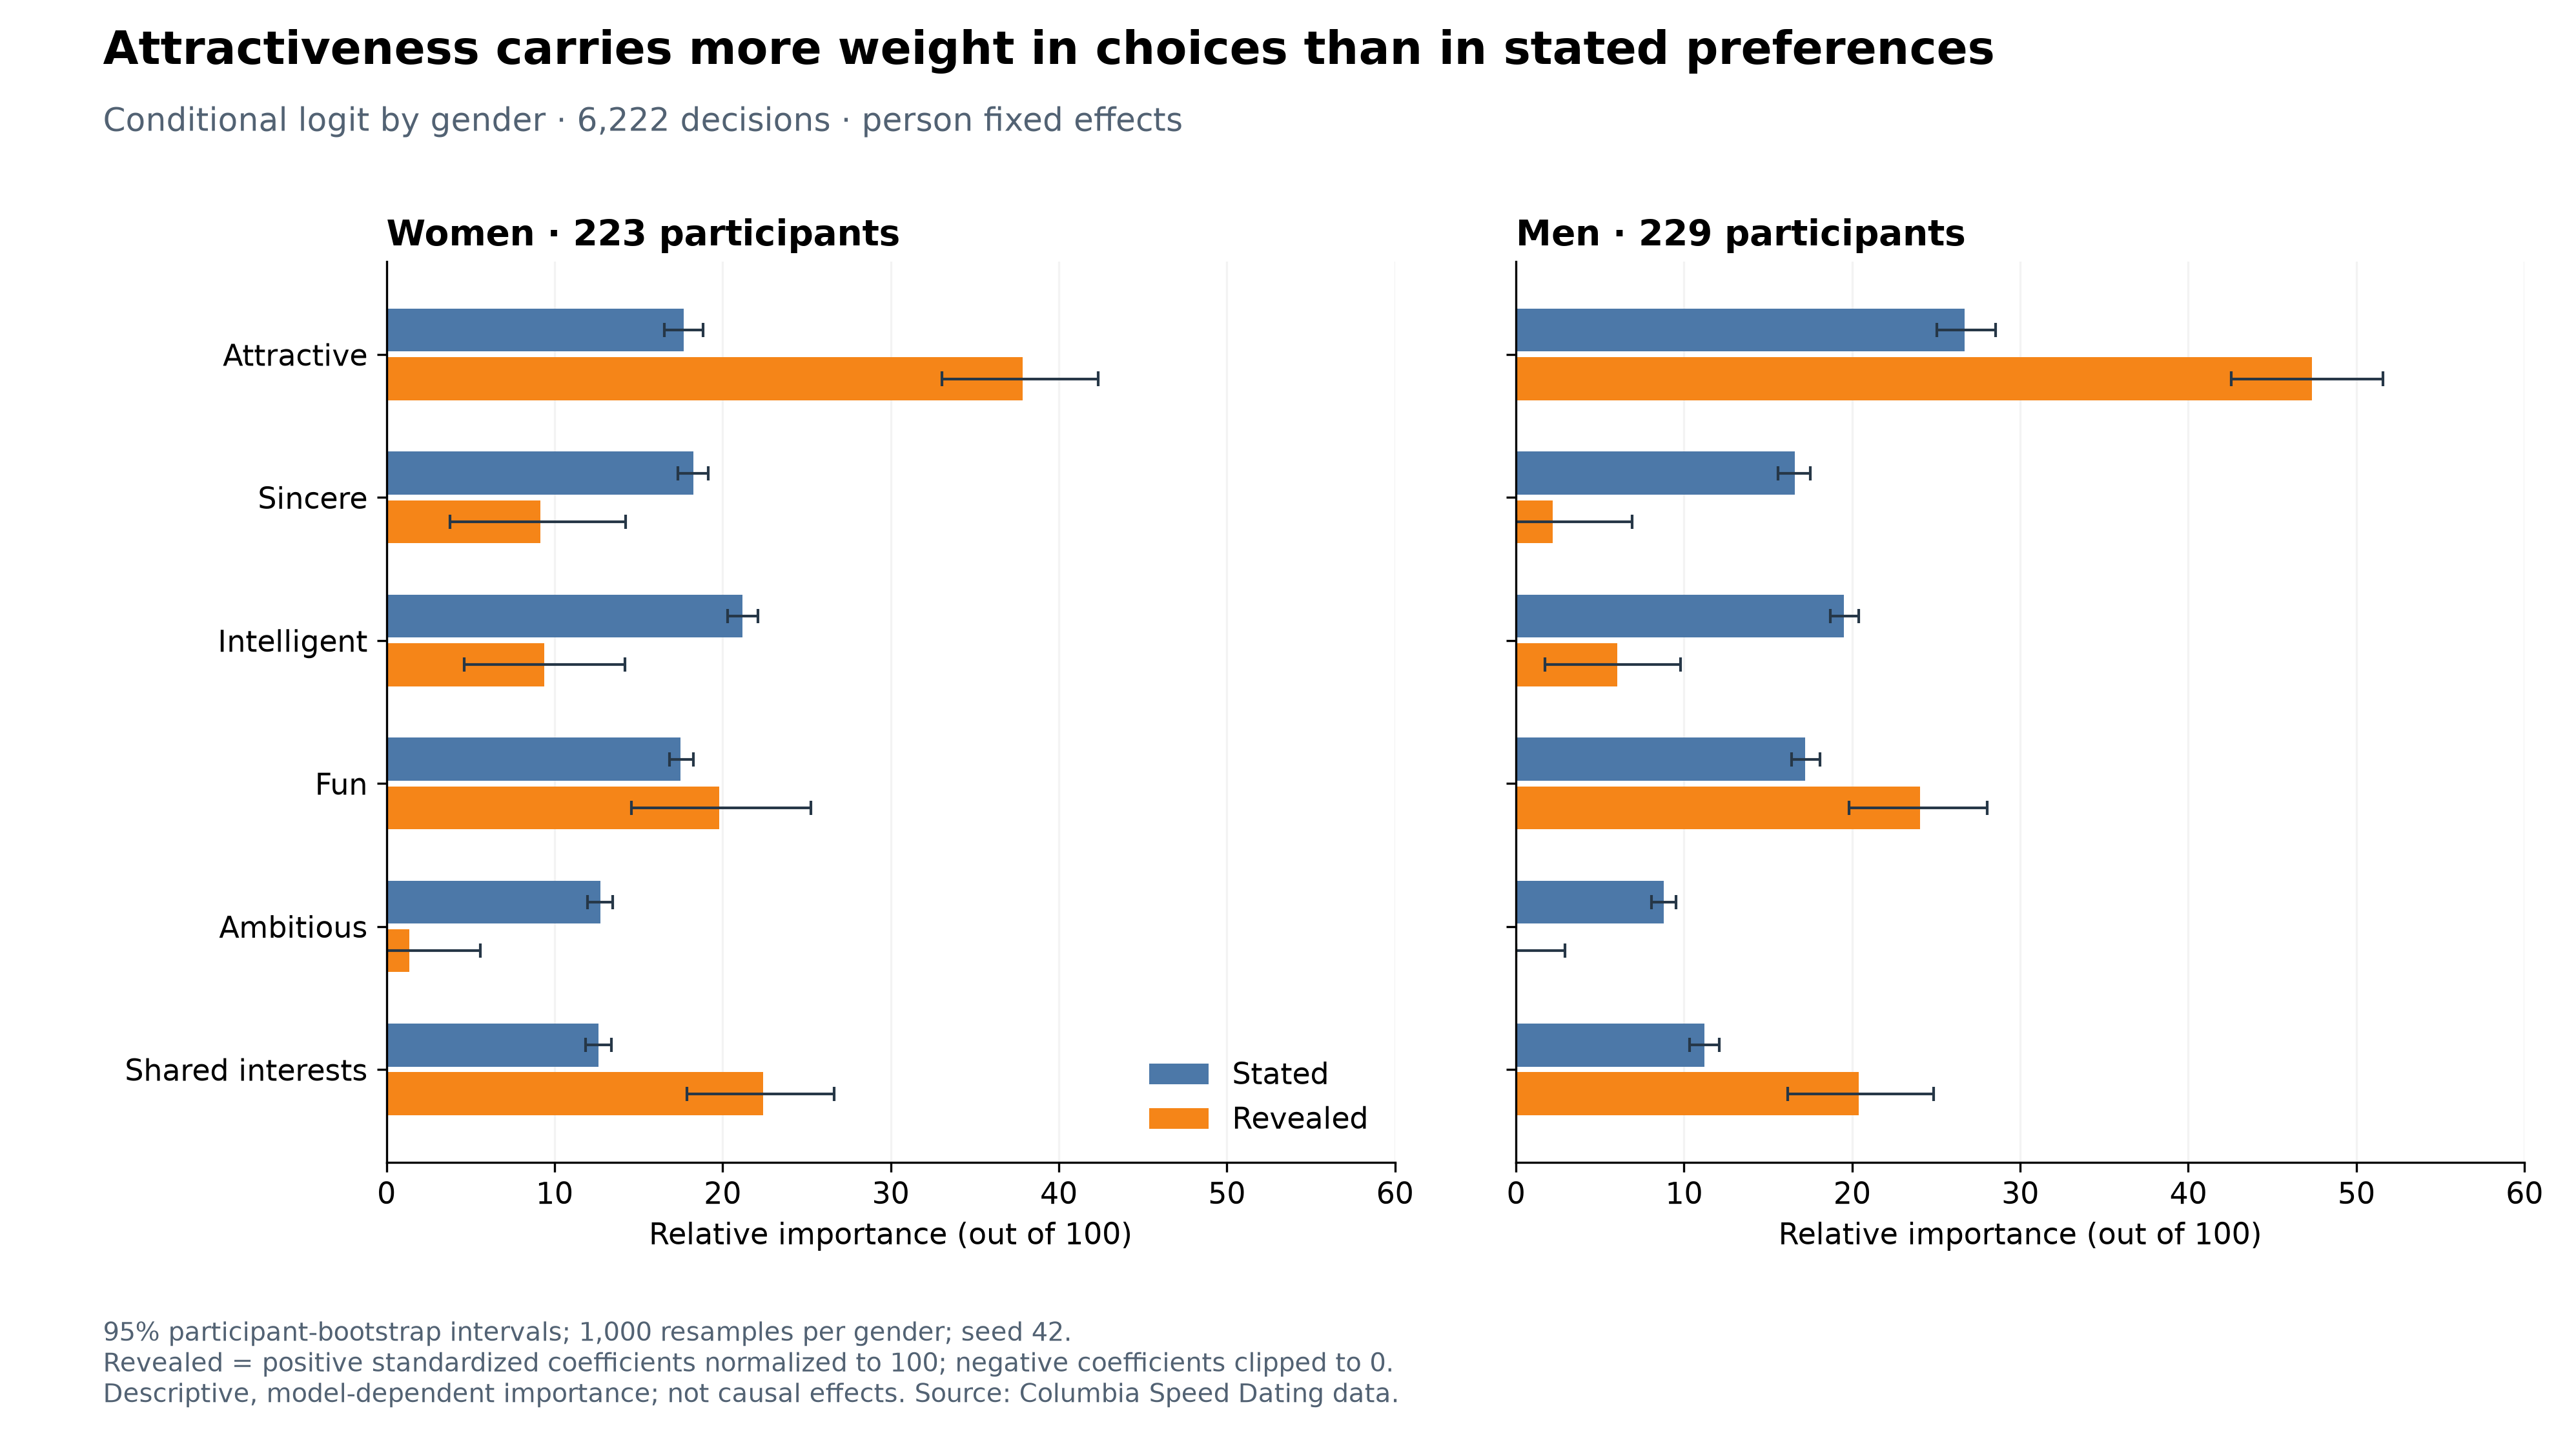

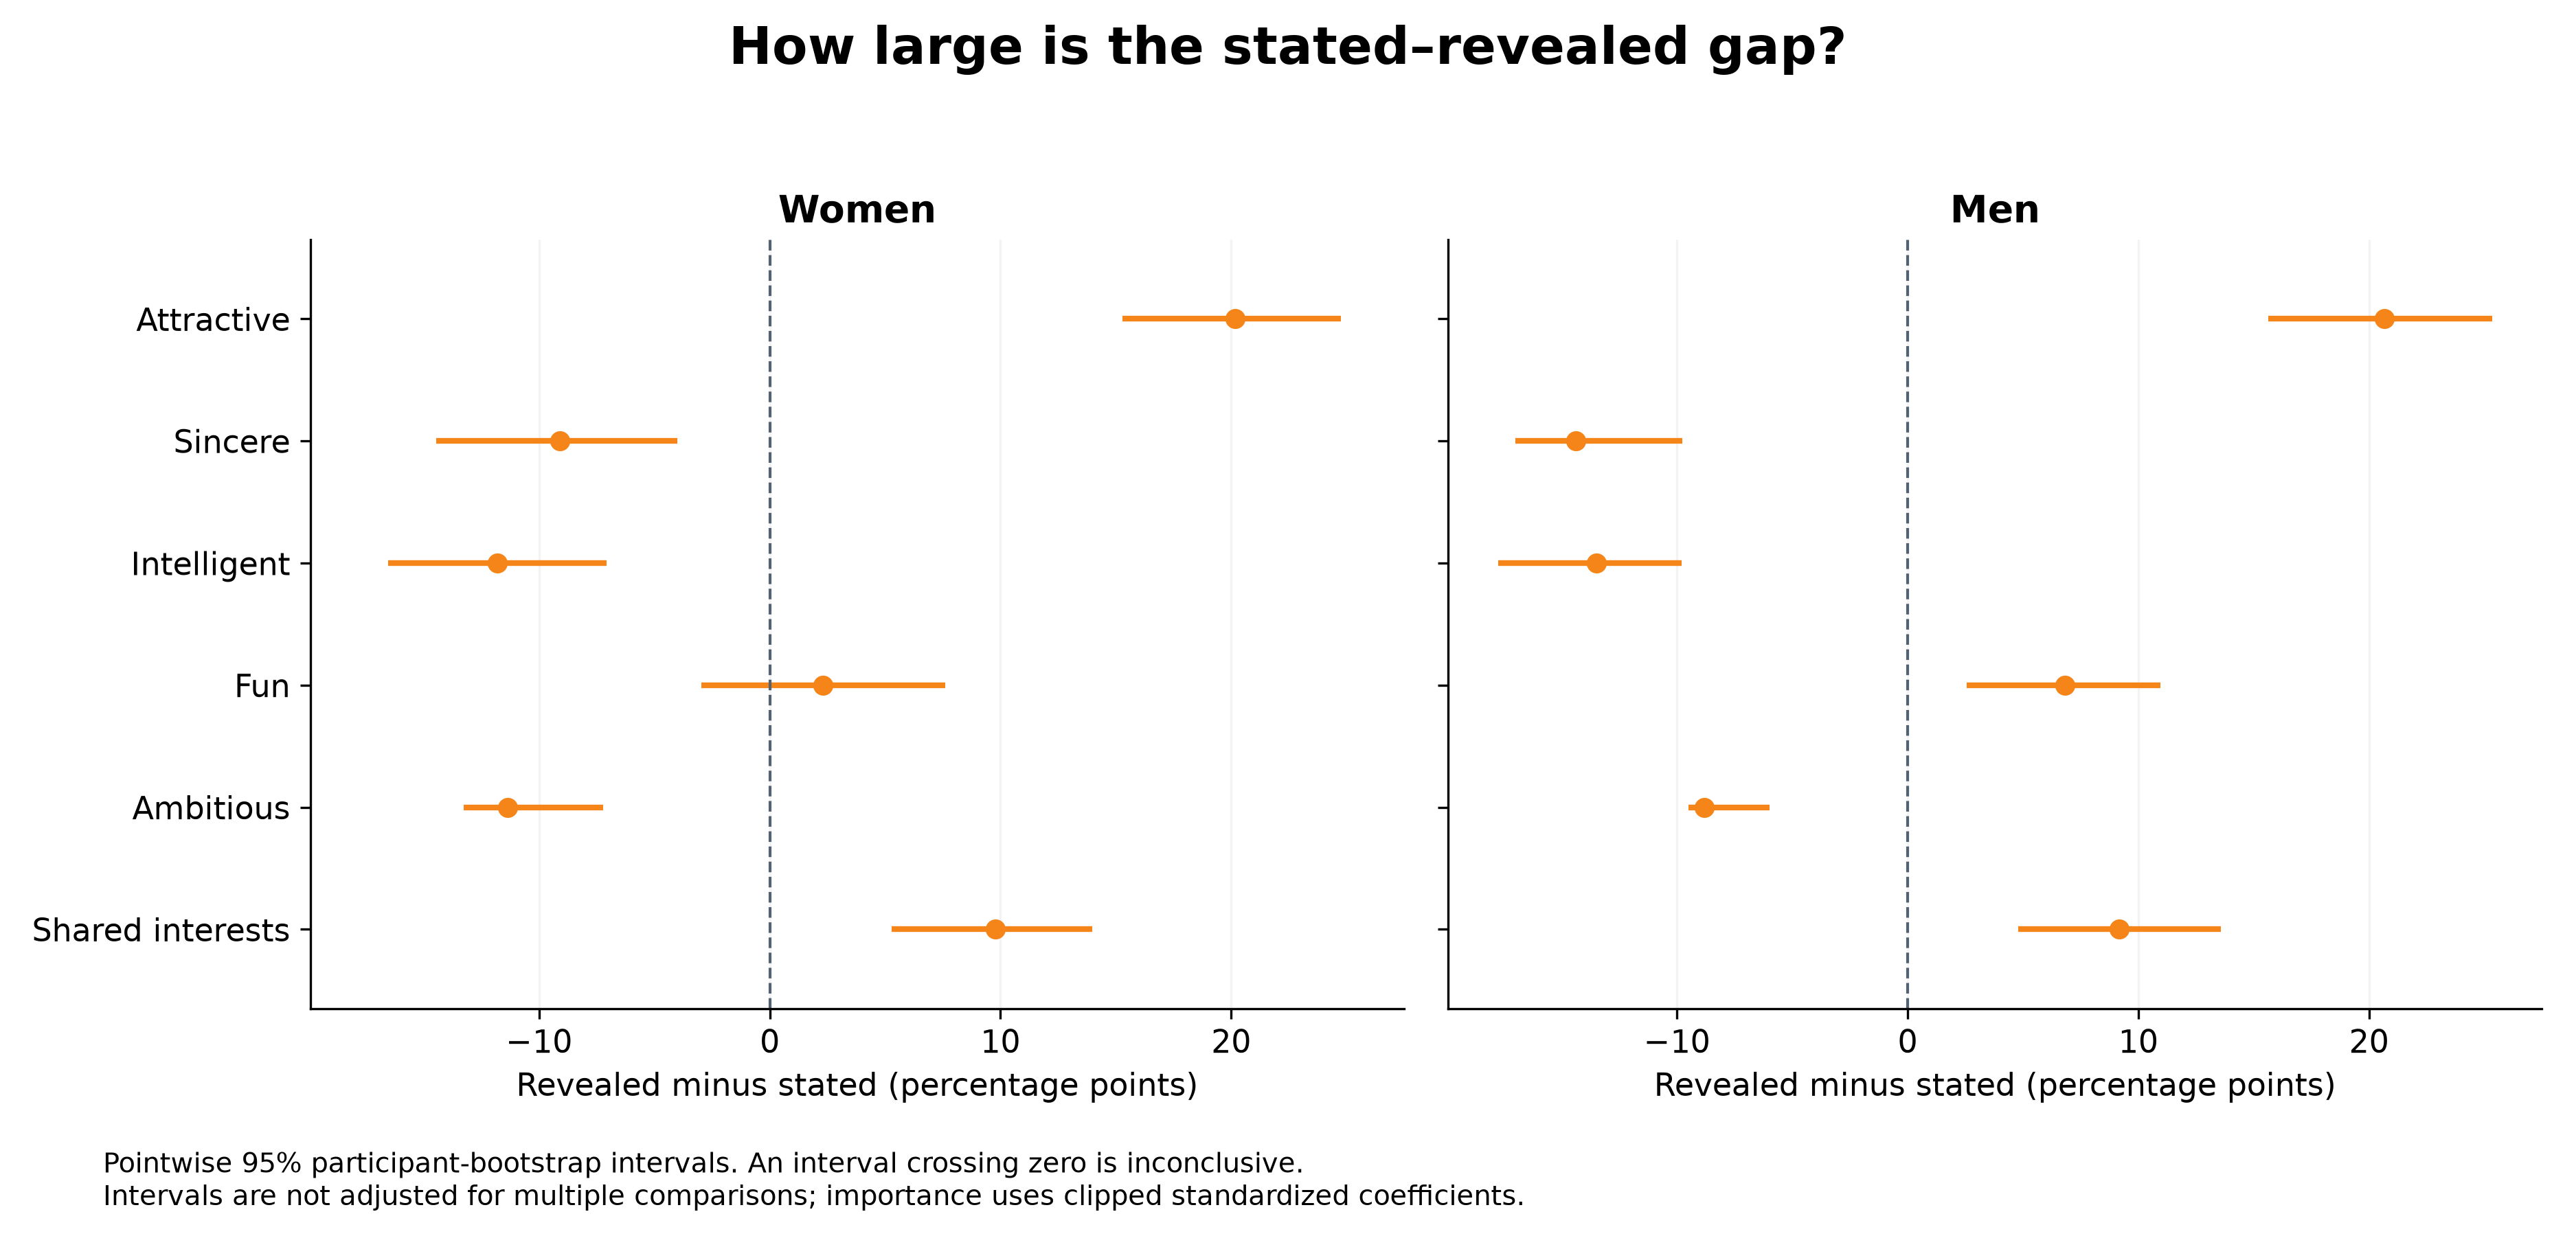

In [4]:
display(Image(filename=str(ROOT / FIGURES_DIR / "core_model_stated_vs_revealed.png"), width=1000))
display(Image(filename=str(ROOT / FIGURES_DIR / "core_model_gap_intervals.png"), width=1000))

## 4. Headline and interpretation

These importance shares compare a stated allocation with a model-based, standardized and clipped coefficient index. They do not measure identical constructs. A negative coefficient being clipped to zero does not establish that the trait is unimportant; inspect signed coefficients and their intervals. Clipping can produce a point mass at zero and nonregular uncertainty near that boundary.

In [5]:
for row in results[results.attribute == "attr"].itertuples():
    print(f"{row.gender}: attractiveness {row.stated:.1f} stated vs {row.revealed:.1f} revealed; gap {row.gap_pp:+.1f} points, 95% CI [{row.gap_ci_low:.1f}, {row.gap_ci_high:.1f}].")
display(results[["gender", "label", "coefficient_std", "coefficient_std_ci_low", "coefficient_std_ci_high", "odds_ratio_per_sd"]].round(3))

Women: attractiveness 17.7 stated vs 37.9 revealed; gap +20.2 points, 95% CI [15.3, 24.8].
Men: attractiveness 26.7 stated vs 47.4 revealed; gap +20.7 points, 95% CI [15.6, 25.3].


,gender,label,coefficient_std,coefficient_std_ci_low,coefficient_std_ci_high,odds_ratio_per_sd
0,Women,Attractive,1.602,1.347,1.893,4.961
1,Women,Sincere,0.388,0.152,0.647,1.474
2,Women,Intelligent,0.397,0.191,0.615,1.487
3,Women,Fun,0.838,0.617,1.061,2.311
4,Women,Ambitious,0.058,-0.131,0.250,1.060
5,Women,Shared interests,0.948,0.748,1.164,2.581
6,Men,Attractive,1.904,1.654,2.222,6.710
7,Men,Sincere,0.088,-0.083,0.288,1.092
8,Men,Intelligent,0.242,0.066,0.415,1.274
9,Men,Fun,0.966,0.796,1.156,2.627


## 5. What to say, and what not to infer

- Survey allocations and the relative attributes associated with yes/no choices differ in this sample. Pair survey research with behavioral validation.
- Post-date ratings can reflect halo effects or chemistry. These are associations, not causal effects of objective attributes and not evidence that respondents lied.
- This is conjoint-style observational choice analysis, not a randomized conjoint experiment.
- Participant bootstrap handles repeated choices by the same person, but shared partners and event conditions can still create cross-person dependence. Event-level sensitivity belongs in the robustness section.
- Missing-data exclusions and the loss of always-yes/always-no participants limit generalization. The sample concerns short speed dates, not long-term relationships.
- There are 12 gap comparisons. Pointwise 95% intervals are exploratory, not a familywise 5% error guarantee.
- Separate gender models do not constitute a formal test of gender differences.
- Differences between survey formats across waves remain a measurement limitation despite normalization.

### Sources

- [Project methodology](../PROJECT_CONTEXT.md)
- [Cleaning audit](../docs/cleaning_audit_verdict.md)
- [Original data key](https://web.mit.edu/17.871/www/2009/speed_dating_codebook.pdf)
- [Statsmodels ConditionalLogit](https://www.statsmodels.org/stable/generated/statsmodels.discrete.conditional_models.ConditionalLogit.html)
- Fisman, Iyengar, Kamenica & Simonson (2006), *Gender Differences in Mate Selection: Evidence From a Speed Dating Experiment*, QJE 121(2), 673–697.

See `docs/core_model_results.md` and `docs/core_model_presentation_notes.md` for the written handoff.